# 05 — Pretrained ResNet18, frozen features (N3)

**Idea (transfer learning).** ResNet18 was trained on 1.2 M ImageNet photos. Its convolutional layers have learned general visual features (edges → textures → patterns → object parts). We keep all of them **frozen** and only train a new linear layer (512 → 5 styles) on top. With 1,050 training images this is the cheapest way to use a deep network.

**In this notebook**
1. Extract the 512-d features of all 1,500 images once (at the native 128 px, and upsampled to 224 px, the ImageNet scale).
2. **Near-duplicate check** across the splits (cosine similarity of the features > 0.95), inspected by eye and reported.
3. Head: a PyTorch `nn.Linear` trained with the shared `fit` (3 seeds) vs a scikit-learn `LogisticRegression` (C tuned on validation).
4. Freeze one frozen-ResNet candidate, measure its CPU latency and size, write `results/resnet_frozen.json`.

The test images go through the feature extractor (for the near-duplicate check only); no prediction is made or scored on them here.

In [1]:
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch  # imported before scikit-learn: see tests/conftest.py
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore", message="Unknown solver options")  # scipy/scikit-learn version noise

FAST_RUN = os.environ.get("FAST_RUN") == "1"
FIG, CKPT, FEAT = "../results/figures", "../checkpoints", "../results/features"
os.makedirs(CKPT, exist_ok=True)
os.makedirs(FEAT, exist_ok=True)
torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True, "lines.linewidth": 2,
                     "font.size": 10, "axes.titlesize": 11, "legend.frameon": False})
print("FAST_RUN =", FAST_RUN)

FAST_RUN = False


In [2]:
import sys

sys.path.insert(0, "../src")
from museum.data import CLASSES, IMAGENET_MEAN, IMAGENET_STD, get_arrays, load_split
from museum.evaluation import benchmark_latency, model_size_mb, plot_confusion, save_result, total_parameters
from museum.models import TorchPredictor, build_resnet18, count_parameters, linear_from_logreg
from museum.train import fit, get_device

device = get_device()
split = load_split()
arrays = {s: get_arrays(128, s) for s in ("train", "val", "test")}
X_train, y_train = arrays["train"]
X_val, y_val = arrays["val"]
paths = {s: split.loc[split.split == s, "path"].to_numpy() for s in arrays}
model = build_resnet18(trainable="head")
print(f"device {device}; ResNet18: {total_parameters(model):,} parameters, "
      f"{count_parameters(model):,} trainable (the head)")

device mps; ResNet18: 11,179,077 parameters, 2,565 trainable (the head)


## 1. Features, extracted once

The backbone runs in eval mode (BatchNorm uses its ImageNet statistics), ImageNet normalisation, on the training device. Features are cached in `results/features/` (ignored by Git) and keyed by image path, so they do not depend on the split.

In [3]:
SIZES = [128, 224]
features, extract_s = {}, {}
for size in SIZES:
    cache = f"{FEAT}/resnet18_{size}.npz"
    predictor = TorchPredictor(model, size, IMAGENET_MEAN, IMAGENET_STD, device=device)
    start = time.perf_counter()
    features[size] = {s: predictor.embed(arrays[s][0]) for s in arrays}
    extract_s[size] = time.perf_counter() - start
    np.savez(cache, **{f"{s}_{k}": v for s in arrays for k, v in
                       (("features", features[size][s]), ("paths", paths[s]))})
    print(f"{size} px: {sum(len(v) for v in features[size].values())} images in {extract_s[size]:.1f} s "
          f"-> {features[size]['train'].shape[1]}-d features")
assert features[128]["train"].shape == (1050, 512)

128 px: 1500 images in 1.4 s -> 512-d features


224 px: 1500 images in 3.9 s -> 512-d features


## 2. Near-duplicate check across splits

Impressionism and Pop Art come from only 1–2 source files of the original dataset, so the same painting (or a crop of it) could appear twice and end up on both sides of the split. That would inflate validation and test accuracy (**leakage**).

Method: cosine similarity between the 512-d features of every pair of images (128 px), flag pairs above **0.95**, then look at them.

In [4]:
all_paths = np.concatenate([paths[s] for s in arrays])
all_split = np.concatenate([[s] * len(paths[s]) for s in arrays])
all_images = np.concatenate([arrays[s][0] for s in arrays])
emb = np.concatenate([features[128][s] for s in arrays])
emb = emb / np.linalg.norm(emb, axis=1, keepdims=True)
sim = emb @ emb.T
np.fill_diagonal(sim, -1)
i, j = np.triu_indices(len(sim), k=1)
pairs = pd.DataFrame({"a": i, "b": j, "cosine": sim[i, j]})
pairs = pairs[pairs.cosine > 0.90].sort_values("cosine", ascending=False)
pairs["splits"] = [" / ".join(sorted((all_split[a], all_split[b]))) for a, b in zip(pairs.a, pairs.b, strict=True)]
pairs["same_class"] = [all_paths[a].split("/")[0] == all_paths[b].split("/")[0]
                       for a, b in zip(pairs.a, pairs.b, strict=True)]
flagged = pairs[pairs.cosine > 0.95]
print(f"{len(i):,} pairs; nearest-neighbour cosine: median {np.median(sim.max(1)):.3f}, max {sim.max():.3f}")
print(f"pairs above 0.95: {len(flagged)}  (above 0.90: {len(pairs)})")
flagged.groupby("splits").size().rename("pairs > 0.95").to_frame()

1,124,250 pairs; nearest-neighbour cosine: median 0.718, max 0.991
pairs above 0.95: 3  (above 0.90: 4)


,pairs > 0.95
splits,
train / train,3


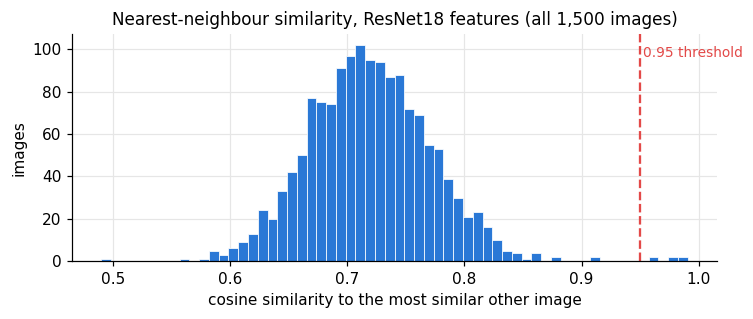

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(sim.max(1), bins=60, color="#2a78d6", edgecolor="white", linewidth=0.5)
ax.axvline(0.95, color="#e34948", linewidth=1.5, linestyle="--")
ax.text(0.952, ax.get_ylim()[1] * 0.9, "0.95 threshold", color="#e34948", fontsize=9)
ax.set_xlabel("cosine similarity to the most similar other image")
ax.set_ylabel("images")
ax.set_title("Nearest-neighbour similarity, ResNet18 features (all 1,500 images)")
fig.tight_layout()
fig.savefig(f"{FIG}/near_duplicates_hist.png", bbox_inches="tight")
plt.show()

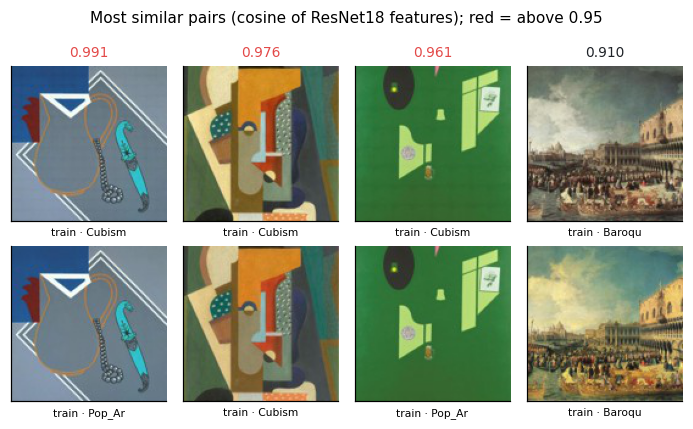

In [6]:
show = pd.concat([flagged, pairs[pairs.cosine <= 0.95]]).head(10)  # every flagged pair first, then the closest others
fig, axes = plt.subplots(2, len(show), figsize=(1.6 * len(show), 3.9), squeeze=False)
for k, (_, row) in enumerate(show.iterrows()):
    for r, idx in enumerate((row.a, row.b)):
        axes[r, k].imshow(all_images[idx])
        axes[r, k].set_xticks([])
        axes[r, k].set_yticks([])
        axes[r, k].set_xlabel(f"{all_split[idx]} · {all_paths[idx].split('/')[0][:6]}", fontsize=7)
    axes[0, k].set_title(f"{row.cosine:.3f}", fontsize=9, color="#e34948" if row.cosine > 0.95 else "#1f2328")
fig.suptitle("Most similar pairs (cosine of ResNet18 features); red = above 0.95", fontsize=10)
fig.tight_layout()
fig.savefig(f"{FIG}/near_duplicates_pairs.png", bbox_inches="tight")
plt.show()

In [7]:
# Saved for 07_comparison: accuracy is also reported without the val/test images that have a near-duplicate in train.
report = flagged.assign(path_a=all_paths[flagged.a], split_a=all_split[flagged.a],
                        path_b=all_paths[flagged.b], split_b=all_split[flagged.b])
report[["path_a", "split_a", "path_b", "split_b", "cosine", "same_class"]].round(4).to_csv(
    "../results/near_duplicates.csv", index=False)
crosses = report[(report.split_a != report.split_b)]
print(f"{len(crosses)} flagged pairs cross a split boundary; written to results/near_duplicates.csv")

0 flagged pairs cross a split boundary; written to results/near_duplicates.csv


## 3. Training the head: `nn.Linear` vs logistic regression

Both heads are linear on the same frozen features, so they are the same family of model; the difference is the training procedure:
- **`nn.Linear` + the shared `fit`**: Adam (lr 1e-3), cross-entropy, mini-batches of 64, early stopping on validation loss (patience 10, best weights restored). Features are standardised with the training mean and std. Three seeds.
- **`LogisticRegression`** (L-BFGS, full batch, L2 penalty), C tuned on validation.

In [8]:
SEEDS = [0] if FAST_RUN else [0, 1, 2]
N_EPOCHS = 5 if FAST_RUN else 200
C_GRID = [1.0] if FAST_RUN else [0.001, 0.01, 0.1, 1.0, 10.0]
loss_fn = nn.CrossEntropyLoss()


def train_linear_head(F_train, F_val, seed):
    torch.manual_seed(seed)
    mean, std = F_train.mean(0), F_train.std(0) + 1e-6
    to_t = lambda F: torch.as_tensor((F - mean) / std, dtype=torch.float32)  # noqa: E731
    gen = torch.Generator().manual_seed(seed)
    train_dl = DataLoader(TensorDataset(to_t(F_train), torch.as_tensor(y_train)), batch_size=64,
                          shuffle=True, generator=gen)
    val_dl = DataLoader(TensorDataset(to_t(F_val), torch.as_tensor(y_val)), batch_size=256)
    head = nn.Linear(F_train.shape[1], len(CLASSES))
    optimizer = torch.optim.Adam(head.parameters(), lr=1e-3)
    history = fit(head, train_dl, val_dl, loss_fn, optimizer, N_EPOCHS, "cpu", patience=10, verbose=False)
    # Fold the standardisation into the layer, so the head takes raw features like the deployed model.
    with torch.no_grad():
        head.bias -= head.weight @ torch.as_tensor(mean / std, dtype=torch.float32)
        head.weight /= torch.as_tensor(std, dtype=torch.float32)
    return head, history


rows, heads, histories = [], {}, {}
for size in SIZES:
    F_train, F_val = features[size]["train"], features[size]["val"]
    for seed in SEEDS:
        start = time.perf_counter()
        head, hist = train_linear_head(F_train, F_val, seed)
        with torch.no_grad():
            acc = float((head(torch.as_tensor(F_val)).argmax(1).numpy() == y_val).mean())
        assert abs(acc - hist["val_acc"][hist["best_epoch"] - 1]) < 1e-9, "folding the scaler changed the head"
        heads[("nn", size, seed)], histories[(size, seed)] = head, hist
        rows.append({"size": size, "head": "nn.Linear", "seed": seed, "C": None, "val_acc": acc,
                     "best_epoch": hist["best_epoch"], "fit_s": time.perf_counter() - start})
    scaler = StandardScaler().fit(F_train)
    for C in C_GRID:
        start = time.perf_counter()
        logreg = LogisticRegression(C=C, max_iter=5000).fit(scaler.transform(F_train), y_train)
        acc = float((logreg.predict(scaler.transform(F_val)) == y_val).mean())
        heads[("logreg", size, C)] = linear_from_logreg(scaler, logreg)
        rows.append({"size": size, "head": "logreg", "seed": None, "C": C, "val_acc": acc,
                     "best_epoch": None, "fit_s": time.perf_counter() - start})
heads_df = pd.DataFrame(rows)
heads_df[heads_df["head"] == "logreg"].pivot(index="C", columns="size", values="val_acc").style.format("{:.3f}")

size,128,224
C,,
0.001000,0.760,0.809
0.010000,0.733,0.840
0.100000,0.711,0.827
1.000000,0.711,0.813
10.000000,0.689,0.800


In [9]:
summary = (heads_df[heads_df["head"] == "nn.Linear"].groupby("size").val_acc.agg(["mean", "std"])
           .rename(columns={"mean": "nn.Linear mean", "std": "nn.Linear std"}))
summary["logreg best"] = heads_df[heads_df["head"] == "logreg"].groupby("size").val_acc.max()
summary["logreg best C"] = heads_df[heads_df["head"] == "logreg"].sort_values("val_acc").groupby("size").C.last()
summary.style.format("{:.3f}", subset=["nn.Linear mean", "nn.Linear std", "logreg best"])

,nn.Linear mean,nn.Linear std,logreg best,logreg best C
size,,,,
128,0.741,0.013,0.760,0.001000
224,0.834,0.018,0.840,0.010000


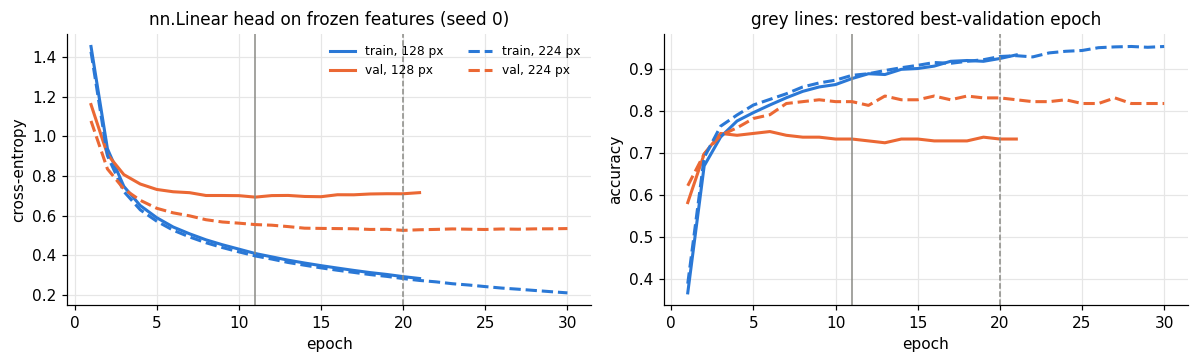

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for size, style in zip(SIZES, ["-", "--"], strict=True):
    hist = histories[(size, 0)]
    epochs = np.arange(1, len(hist["train_loss"]) + 1)
    axes[0].plot(epochs, hist["train_loss"], color="#2a78d6", linestyle=style, label=f"train, {size} px")
    axes[0].plot(epochs, hist["val_loss"], color="#eb6834", linestyle=style, label=f"val, {size} px")
    axes[1].plot(epochs, hist["val_acc"], color="#eb6834", linestyle=style, label=f"val, {size} px")
    axes[1].plot(epochs, hist["train_acc"], color="#2a78d6", linestyle=style, label=f"train, {size} px")
    for ax in axes:
        ax.axvline(hist["best_epoch"], color="#8a8a85", linewidth=1, linestyle=style)
axes[0].set(xlabel="epoch", ylabel="cross-entropy", title="nn.Linear head on frozen features (seed 0)")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="grey lines: restored best-validation epoch")
axes[0].legend(ncols=2, fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIG}/resnet_frozen_curves.png", bbox_inches="tight")
plt.show()

## 4. Latency of the frozen model, then the candidate

The head is tiny (2,565 parameters); the cost is the ResNet18 forward pass, measured end to end on one raw 128 px image (resize if needed, normalisation, network), batch 1, CPU, 1 and 2 threads. It depends only on the input size, not on the head.

**Selection rule, fixed before training:** the highest validation accuracy among the options whose 1-thread median latency is ≤ 40 ms (the kiosk budget of 200 ms divided by the ×5 safety factor, PLAN §4). For `nn.Linear` the score is the mean over the 3 seeds and the seed-0 weights are frozen; for logistic regression it is the best C. Ties go to the smaller input, then to logistic regression (deterministic).

In [11]:
runs = 20 if FAST_RUN else 100
cpu_model = build_resnet18(trainable="head").eval()
sample = X_val[0]
latency = {}
for size in SIZES:
    predictor = TorchPredictor(cpu_model, size, IMAGENET_MEAN, IMAGENET_STD)
    latency[size] = {f"threads_{t}": benchmark_latency(predictor, sample, n_threads=t, runs=runs) for t in (1, 2)}
pd.DataFrame({size: {k: v["median_ms"] for k, v in lat.items()} for size, lat in latency.items()}).round(1)

,128,224
threads_1,9.8,19.1
threads_2,8.7,14.5


In [12]:
options = []
for size in SIZES:
    ok = latency[size]["threads_1"]["median_ms"] <= 40
    nn_rows = heads_df[(heads_df["head"] == "nn.Linear") & (heads_df["size"] == size)]
    lr_rows = heads_df[(heads_df["head"] == "logreg") & (heads_df["size"] == size)]
    best_lr = lr_rows.sort_values(["val_acc", "C"], ascending=[False, True]).iloc[0]
    options.append({"size": size, "head": "nn.Linear", "score": nn_rows.val_acc.mean(), "key": ("nn", size, 0),
                    "latency_ok": ok, "tie": 1})
    options.append({"size": size, "head": "logreg", "score": best_lr.val_acc, "key": ("logreg", size, best_lr.C),
                    "latency_ok": ok, "tie": 0})
options = pd.DataFrame(options)
choice = options[options.latency_ok].sort_values(["score", "size", "tie"], ascending=[False, True, True]).iloc[0]
print(options.drop(columns="key").round(3).to_string(index=False))
print(f"\nchosen: {choice['head']} head at {choice['size']} px (validation score {choice.score:.3f})")

 size      head  score  latency_ok  tie
  128 nn.Linear  0.741        True    1
  128    logreg  0.760        True    0
  224 nn.Linear  0.834        True    1
  224    logreg  0.840        True    0

chosen: logreg head at 224 px (validation score 0.840)


frozen ResNet candidate, end to end on raw images: val acc 0.840


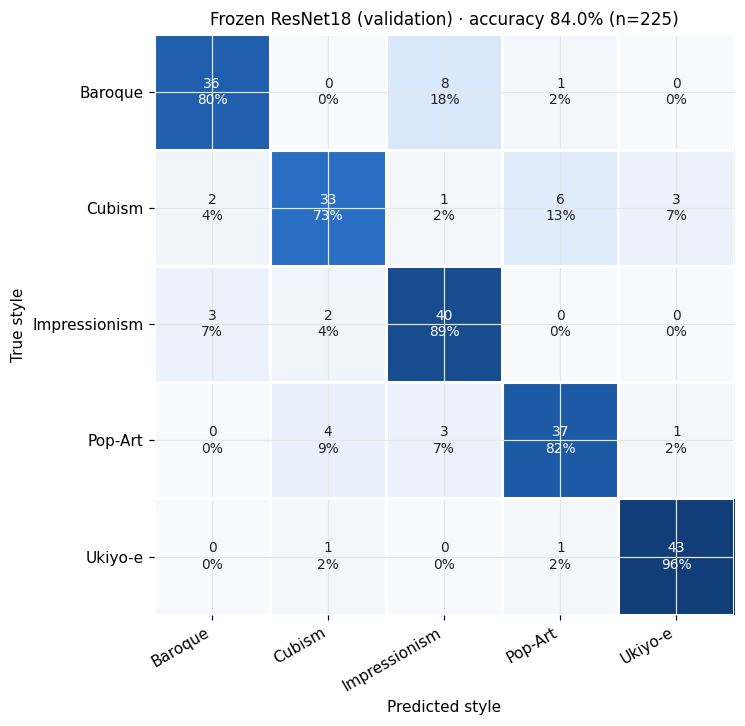

In [13]:
SIZE = int(choice["size"])
candidate = build_resnet18(trainable="head")
candidate.net.fc.load_state_dict(heads[choice.key].state_dict())
predictor = TorchPredictor(candidate, SIZE, IMAGENET_MEAN, IMAGENET_STD, device=device)
val_pred = predictor.predict(X_val)
val_acc = float((val_pred == y_val).mean())
expected = heads_df[(heads_df["size"] == SIZE) & (heads_df["head"] == choice["head"])]
expected = expected[(expected.seed == 0) | (expected.C == choice.key[2])].val_acc.iloc[0]
assert abs(val_acc - expected) <= 1 / len(y_val), (val_acc, expected)  # end to end = features + head
print(f"frozen ResNet candidate, end to end on raw images: val acc {val_acc:.3f}")
plot_confusion(y_val, val_pred, CLASSES, f"{FIG}/resnet_frozen_val_confusion.png", title="Frozen ResNet18 (validation)")

In [14]:
torch.save({"state_dict": candidate.state_dict(), "img_size": SIZE, "trainable": "head"}, f"{CKPT}/resnet_frozen.pt")
nn_stats = heads_df[(heads_df["head"] == "nn.Linear") & (heads_df["size"] == SIZE)].val_acc
head_time = heads_df[(heads_df["size"] == SIZE) & (heads_df["head"] == choice["head"])].fit_s.iloc[0]
path = save_result("resnet_frozen", {
    "config": {"img_size": SIZE, "head": choice["head"], "C": choice.key[2] if choice["head"] == "logreg" else None,
               "normalize": "imagenet", "weights": "IMAGENET1K_V1",
               "nn_linear_val_acc_mean": float(nn_stats.mean()), "nn_linear_val_acc_std": float(nn_stats.std()),
               "logreg_best_val_acc": float(summary.loc[SIZE, "logreg best"]),
               "trainable_params": 512 * 5 + 5, "seeds": SEEDS, "fast_run": FAST_RUN,
               "near_duplicate_pairs_over_0.95": int(len(flagged)),
               "near_duplicate_pairs_crossing_splits": int(len(crosses))},
    "val_acc": val_acc, "n_params": total_parameters(candidate), "size_mb": model_size_mb(f"{CKPT}/resnet_frozen.pt"),
    "latency_ms": latency[SIZE],
    # training cost = feature extraction (all images, both sizes timed separately) + fitting the head
    "train_time_s": extract_s[SIZE] + head_time,
})
print("wrote", path.relative_to(path.parents[1]))

wrote results/resnet_frozen.json


## What we see

- **Frozen ImageNet features are already strong**: a linear head on them reaches about 84 % validation accuracy at 224 px, against 55 % for the classical baseline (`results/classical.json`), with only 2,565 trained numbers. Features learned on photos transfer to paintings: style is largely texture, stroke and colour statistics, which the convolutional layers already encode.
- **224 px is clearly better than 128 px** here (about +8 to +9 points for both heads), although upsampling adds no detail: the ImageNet filters work best at the object scale they were trained on. It costs about 2× the latency, still inside the 40 ms budget.
- **The two heads agree** (they are the same linear model, trained differently): `nn.Linear` 0.834 ± 0.018 over 3 seeds vs logistic regression 0.840 at 224 px. The gap is smaller than the seed spread, i.e. noise; the rule picks logistic regression (best score, deterministic).
- **Near-duplicates — no leakage, but label noise.** The nearest-neighbour similarities form one bulk around 0.72 with a clear gap; only **3 pairs exceed 0.95**, and the figure shows they are the *same image* stored twice. All 3 pairs are **inside the training set**, so no validation or test image has a copy in train: our scores are not inflated by memorisation. But **2 of the 3 pairs carry different labels** (the same picture labelled Cubism *and* Pop Art): the WikiArt style labels themselves are noisy, which caps the accuracy any model can reach.
- **Grid edge**: at 128 px the best logistic-regression C is the smallest tried (0.001); that option is 8 points below the 224 px candidate, so a wider grid cannot change the choice.
- **The cost is the backbone**: about 19 ms per image on one CPU thread at 224 px, 45 MB on disk — inside the budget, but about 6× slower and 3× larger than the classical model. (Laptop timings vary by 10–20 % between runs, e.g. when the OS indexes files; the margin to the 40 ms budget is much larger than that.)